## Load Model

In [2]:
%load_ext autoreload
%autoreload 2
%matplotlib widget
import torch, pandas as pd
import numpy as np
from pathlib import Path
from src.Diffusion1d import *
from src.trainloop import build_model, build_ema, load_checkpoint
from src.DataPipeline import DataPipeline
from src.ConditioningDropout import CondDropout

device = "cuda" if torch.cuda.is_available() else "cpu"

In [3]:
run_dir = Path(r"../outputs/runs/20261029_182156_0bb913")

manifest = pd.read_csv(r"../data/manifests/realized_manifest_cleaned.csv", index_col=0)
manifest, appliances = add_appliance_shares(manifest)

pipe = DataPipeline.load_files(run_dir / "data", manifest)
cfg = pipe.cfg
print(pipe.split_hash)

buildings -> train 2730, val 585, test 585
rows-> train 8189, val 1755, test 1755
rows-> holdout_building 300, holdout_year 3897, holdout_both 100
Missing Files: 7185
Existing Files: 1004
Total: 8189
Missing Files: 1528
Existing Files: 227
Total: 1755
Missing Files: 1531
Existing Files: 224
Total: 1755
Missing Files: 261
Existing Files: 39
Total: 300
Missing Files: 3407
Existing Files: 490
Total: 3897
Missing Files: 84
Existing Files: 16
Total: 100
1015ddb8d77a


In [5]:
ckpt = load_checkpoint(run_dir / "final.pt", map_location=device)   # or last.pt / epoch_050.pt
c = ckpt["config"]

assert c["split_hash"] == pipe.split_hash          # checkpoint and data pipeline belong together
assert c["model"]["n_dyn_cond_cols"] == cfg.n_dyn_model_cols

model = build_model(c["model"], device)
ema = build_ema(model, c["ema"])
model.load_state_dict(ckpt["model"])
ema.load_state_dict(ckpt["ema"])
net = ema.ema_model.eval()                         # use EMA weights for sampling, as validation does

schedule = DiffusionSchedule.make(c["schedule"], timesteps=c["timesteps"]).to(device)
x0_min, x0_max = ckpt["extras"]["x0_min"], ckpt["extras"]["x0_max"]

In [6]:
split = "train"                                     # or "val", "holdout_building", "holdout_year", "holdout_both"
idx = pipe.Window_drawer(split, n_runs=20, n_windows=12, seed=0)
ds = pipe.windowdataset(split, idx)
dl = pipe.dataloader(ds, batchsize=32, num_workers=0)

In [19]:
cond = CondDropout.from_config(cfg)

In [7]:
batches = iter(dl)

In [8]:
from src.Evaluation import decode_static
batch = next(batches)
trgt = batch["target"].to(device)
dyn = batch["condition"].to(device)
static_cat  = batch["static_cat"].to(device)
static_cont = batch["static_cont"].to(device)
static_bool = batch["static_bool"].to(device)
decode_static(pipe.preprocessor, static_cat, static_cont, static_bool)

,buildingType,buildingAgeBin,year_type,climateRegion,n_persons_sum,a_ref,n_apartments,apl_ANSWER_MACHINE,apl_CD_PLAYER,apl_CHEST_FREEZER,...,apl_RECEIVER,apl_TUMBLE_DRYER,apl_TV1,apl_TV2,apl_TV3,apl_UPRIGHT_FREEZER,apl_VACUUM,apl_VCR_DVD,apl_WASHER_DRYER,apl_WASHING_MACHINE
0,AB,DE.02,average,15,25.0,1172.026978,16.0,0.750000,0.875,0.187500,...,0.937500,0.312500,1.0,0.750000,0.187500,0.437500,1.000000,0.937500,0.187500,1.000000
1,AB,DE.02,average,15,25.0,1172.026978,16.0,0.750000,0.875,0.187500,...,0.937500,0.312500,1.0,0.750000,0.187500,0.437500,1.000000,0.937500,0.187500,1.000000
2,AB,DE.02,average,15,25.0,1172.026978,16.0,0.750000,0.875,0.187500,...,0.937500,0.312500,1.0,0.750000,0.187500,0.437500,1.000000,0.937500,0.187500,1.000000
3,AB,DE.02,average,15,25.0,1172.026978,16.0,0.750000,0.875,0.187500,...,0.937500,0.312500,1.0,0.750000,0.187500,0.437500,1.000000,0.937500,0.187500,1.000000
4,AB,DE.02,average,15,25.0,1172.026978,16.0,0.750000,0.875,0.187500,...,0.937500,0.312500,1.0,0.750000,0.187500,0.437500,1.000000,0.937500,0.187500,1.000000
5,AB,DE.02,average,15,25.0,1172.026978,16.0,0.750000,0.875,0.187500,...,0.937500,0.312500,1.0,0.750000,0.187500,0.437500,1.000000,0.937500,0.187500,1.000000
6,AB,DE.02,average,15,25.0,1172.026978,16.0,0.750000,0.875,0.187500,...,0.937500,0.312500,1.0,0.750000,0.187500,0.437500,1.000000,0.937500,0.187500,1.000000
7,AB,DE.02,average,15,25.0,1172.026978,16.0,0.750000,0.875,0.187500,...,0.937500,0.312500,1.0,0.750000,0.187500,0.437500,1.000000,0.937500,0.187500,1.000000
8,AB,DE.02,average,15,25.0,1172.026978,16.0,0.750000,0.875,0.187500,...,0.937500,0.312500,1.0,0.750000,0.187500,0.437500,1.000000,0.937500,0.187500,1.000000
9,AB,DE.02,average,15,25.0,1172.026978,16.0,0.750000,0.875,0.187500,...,0.937500,0.312500,1.0,0.750000,0.187500,0.437500,1.000000,0.937500,0.187500,1.000000


In [68]:
dyn.shape

torch.Size([32, 10, 1440])

In [96]:
x_gen = sample1d(
    net,                                                  # EMA model from cell 3
    sequence_length=cfg.window_length,
    batch_size=dyn.shape[0],
    channels=len(cfg.target_cols),
    schedule=schedule,
    static_cat=static_cat, static_cont=static_cont, static_bool=static_bool,
    dyn=dyn,
    clip_range=(x0_min, x0_max),                          # or None, as in your training notebook
)                                                         # returns a CPU tensor (B, C, L), scaled space
n_dyn = len(cfg.dynamic_cond_cols)
condition = invert_scaler(batch["condition"][:, :n_dyn], pipe.condition_scaler) * batch["condition_norm"]

K = cfg.context_steps
n_dyn, n_tgt = len(cfg.dynamic_cond_cols), len(cfg.target_cols)
s0 = n_dyn + (2 if cfg.use_season else 0)                  # first context channel (after dynamic and season)

cond = batch["condition"]
has_ctx = cond[:, s0 + n_tgt, 0] > 0                       # mask, (B,): False if no previous day or dropped
ctx = cond[:, s0:s0 + n_tgt, :K]                           # (B, n_tgt, K), scaled
ctx = invert_scaler(ctx, pipe.target_scaler) * batch["target_norm"]   # back to original units
if cfg.context_reverse:
    ctx = ctx.flip(-1)                                     # chronological order again
t_ctx = np.arange(-K, 0)                                   # context sits just before the window

x = invert_scaler(x_gen, pipe.target_scaler) * batch["target_norm"]
real = invert_scaler(batch["target"], pipe.target_scaler) * batch["target_norm"]


sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

In [10]:
train_df_exist, val_df_exist, test_df_exist = (pipe.split_dfs[s] for s in ("train", "val", "test"))
train_files, train_run_ids, train_static = (pipe.prepare_data("train")[k] for k in ("files", "run_ids", "static"))
val_files, val_run_ids, val_static = (pipe.prepare_data("val")[k] for k in ("files", "run_ids", "static"))
test_files, test_run_ids, test_static = (pipe.prepare_data("test")[k] for k in ("files", "run_ids", "static"))

In [97]:
print("gen  mean/std per channel:", x_gen.mean(dim=(0, 2)), x_gen.std(dim=(0, 2)))
print("real mean/std per channel:", batch["target"].mean(dim=(0, 2)), batch["target"].std(dim=(0, 2)))

gen  mean/std per channel: tensor([-0.0967, -0.1626,  0.7419]) tensor([1.0779, 0.5297, 1.1879])
real mean/std per channel: tensor([-0.0669, -0.1633,  0.8611]) tensor([1.1552, 0.5426, 1.2778])


In [12]:
import torch
from src.Diffusion1d import sample1d
cond = CondDropout.from_config(cfg)
@torch.no_grad()
def eval_cfg(net, pipe, cond, loader, schedule, device, keep=None, scale=1.0, n_batches=2):
    cfg = pipe.cfg
    n_tgt, K, m = len(cfg.target_cols), cfg.context_steps, cfg.context_mask_idx
    first = 0 if cfg.context_reverse else K - 1            # slot of the newest context minute
    clip = pipe.x0_minmax()
    gap_g, gap_r, bias = [], [], []
    for i, b in enumerate(loader):
        if i >= n_batches:
            break
        x, dyn = b["target"].to(device), b["condition"].to(device)
        args = [b[k].to(device) for k in ("static_cat", "static_cont", "static_bool")]
        g = sample1d(net, x.shape[-1], x.shape[0], n_tgt, schedule, *args, dyn=dyn,
                     clip_range=clip, cond=cond, keep=keep, scale=scale).to(device)
        has = dyn[:, m, first] > 0                           # windows that have context
        last = dyn[:, m - n_tgt:m, first]
        gap_g.append((g[:, :, 0] - last)[has].abs())
        gap_r.append((x[:, :, 0] - last)[has].abs())
        bias.append((g - x).mean(-1))
    f = lambda l: torch.cat(l).mean(0).cpu().numpy().round(3)
    return dict(gap_gen=f(gap_g), gap_real=f(gap_r), bias=f(bias))

for keep, scale in [(None, 1.0), (None, 2.0), ({"temperature": False}, 1.0), ({"temperature": False}, 2.0)]:
    print(keep, scale, eval_cfg(net, pipe, cond, dl, schedule, device, keep=keep, scale=scale))

sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

None 1.0 {'gap_gen': array([0.336, 0.484, 0.368], dtype=float32), 'gap_real': array([0.129, 0.14 , 0.002], dtype=float32), 'bias': array([ 0.025, -0.018,  0.452], dtype=float32)}


sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

...

sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

{'temperature': False} 1.0 {'gap_gen': array([0.329, 1.006, 0.364], dtype=float32), 'gap_real': array([0.129, 0.14 , 0.002], dtype=float32), 'bias': array([ 0.031, -0.008,  0.251], dtype=float32)}


sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

{'temperature': False} 2.0 {'gap_gen': array([0.244, 1.054, 0.483], dtype=float32), 'gap_real': array([0.129, 0.14 , 0.002], dtype=float32), 'bias': array([0.126, 0.13 , 0.489], dtype=float32)}


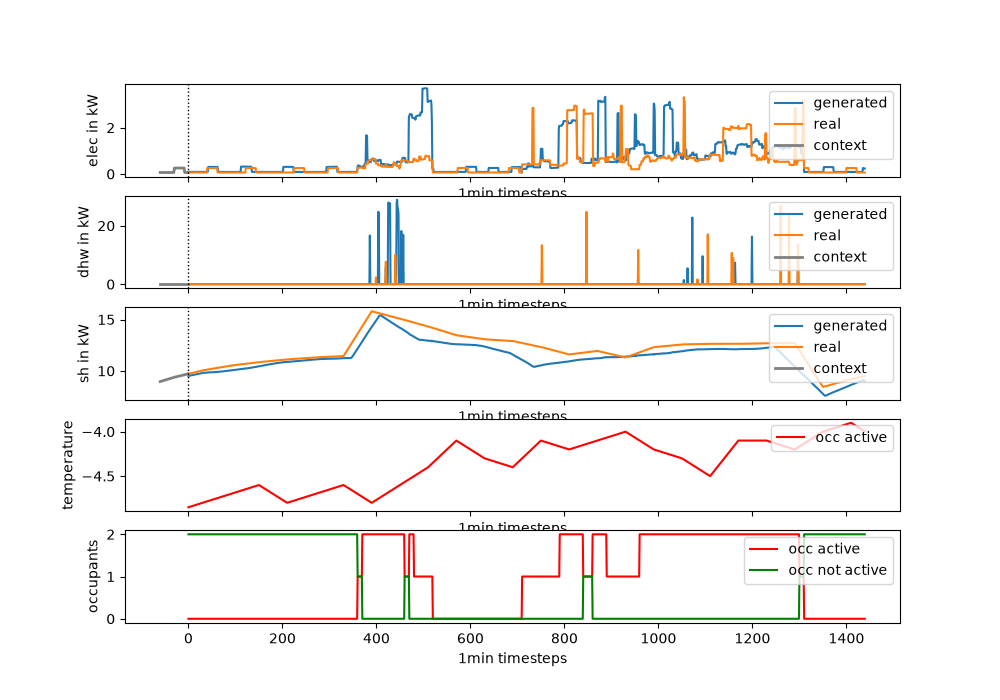

In [104]:
i =17

occ = condition[i]
load = x[i]
load_real = real[i]

occ_activ, occ_not_active, temp = occ[0],occ[1], occ[2]
elec_gen, dhw_gen, sh_gen = load[0], load[1], load[2]
elec_real, dhw_real, sh_real = load_real [0], load_real [1], load_real [2]


fig, ax = plt.subplots(5,1, figsize=(10,7), sharex=True)

ax[0].plot(elec_gen, label="generated")
ax[0].plot(elec_real, label="real")
ax[0].set_ylabel("elec in kW")
ax[0].set_xlabel("1min timesteps")


ax[1].plot(dhw_gen, label="generated")
ax[1].plot(dhw_real, label="real")
ax[1].set_ylabel("dhw in kW")
ax[1].set_xlabel("1min timesteps")


ax[2].plot(sh_gen, label="generated")
ax[2].plot(sh_real, label="real")
ax[2].set_ylabel("sh in kW")
ax[2].set_xlabel("1min timesteps")


ax[3].plot(temp, label="occ active", color="r")
ax[3].set_ylabel("temperature")
ax[3].set_xlabel("1min timesteps")
ax[3].legend(loc="upper right")

ax[4].plot(occ_activ, label="occ active", color="r")
ax[4].plot(occ_not_active, label="occ not active", color="g")
ax[4].set_ylabel("occupants")
ax[4].set_xlabel("1min timesteps")
ax[4].legend(loc="upper right")

for k in range(3):
    if has_ctx[i]:
        ax[k].plot(t_ctx, ctx[i, k], color="gray", lw=2, label="context")
    ax[k].axvline(0, color="k", ls=":", lw=1)
    ax[k].legend(loc="upper right")


In [62]:
from src.trainloop import validate

val_idx = pipe.Window_drawer("val", 1, 1, seed=0)          # the same draw as val_dataset_eval in training
val_dl = pipe.dataloader(pipe.windowdataset("val", val_idx), batchsize=32, num_workers=0)
val_loss, val_per_t = validate(net, schedule, val_dl, device, loss_type=c["loss_type"], n_batches=None)
print(val_loss, "| step:", ckpt["global_step"])

0.05090952180636425 | step: 22896


In [72]:
import numpy as np
res = []
for b_i, batch in zip(range(16), dl):
    dyn = batch["condition"].to(device)
    x_gen = sample1d(net, cfg.window_length, dyn.shape[0], n_tgt, schedule,
                     batch["static_cat"].to(device), batch["static_cont"].to(device), batch["static_bool"].to(device),
                     dyn=dyn, clip_range=(x0_min, x0_max))
    cond = batch["condition"]
    has = cond[:, s0 + n_tgt, 0] > 0
    last = cond[:, s0:s0 + n_tgt, 0 if cfg.context_reverse else K - 1]     # last context step, scaled
    res.append(dict(
        bias=(x_gen.mean(2) - batch["target"].mean(2)),                      # (B, n_tgt)
        gap_gen=(x_gen[:, :, 0] - last).abs()[has],
        gap_real=(batch["target"][:, :, 0] - last).abs()[has]))
print("mean bias per channel:", torch.cat([r["bias"] for r in res]).mean(0))
print("boundary gap gen :", torch.cat([r["gap_gen"] for r in res]).mean(0))
print("boundary gap real:", torch.cat([r["gap_real"] for r in res]).mean(0))

sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

...

sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

mean bias per channel: tensor([-0.0203, -0.0039, -0.0019])
boundary gap gen : tensor([0.2618, 0.0795, 0.0262])
boundary gap real: tensor([0.1533, 0.0385, 0.0033])


In [106]:
cfg.window_length

1440

In [11]:
def year_conditions(ds, run_id, path, window_length):
    """Scaled dynamic conditions for the whole year, split into days: list of (1, n_dyn[+2], L)."""
    _, cond, season = ds._read_series(path)
    cond = apply_scaler(cond / ds.condition_norm[run_id], ds.condition_scaler)
    if season is not None:                       # appended after scaling, like in h5Dataset
        cond = np.concatenate([cond, season], axis=0)
    n_days = cond.shape[1] // window_length
    return [torch.from_numpy(np.ascontiguousarray(
                cond[:, d * window_length:(d + 1) * window_length]))[None].float()
            for d in range(n_days)]


days = year_conditions(ds, train_run_ids[-1], train_files[-1], cfg.window_length)

In [13]:
B = 8
dyn_days = [d.repeat(B, 1, 1).to(device) for d in days]
static = train_static[train_run_ids[-1]]                                         # same dict h5Dataset uses
static_cat  = static["categorical"][None].repeat(B, 1).to(device)
static_cont = static["continuous"][None].repeat(B, 1).to(device)
static_bool = static["boolean"][None].repeat(B, 1).to(device)

In [14]:
static

{'categorical': tensor([ 4, 12,  1, 12]),
 'continuous': tensor([-0.8318, -0.8818, -0.8329,  0.4573, -4.0817, -0.5860,  0.4621,  2.0336,
          2.7742,  1.5905,  1.0150,  0.4435,  1.4325,  0.4369,  0.2242,  0.5517,
         -1.7566,  0.8743,  0.4535, -1.9020,  0.3780,  1.6788,  0.2031,  1.1364,
         -0.6089, -0.8404,  0.3620,  0.4646, -0.5622, -2.4214]),
 'boolean': tensor([])}

In [22]:
static_cat

tensor([[ 4, 12,  1, 12],
        [ 4, 12,  1, 12],
        [ 4, 12,  1, 12],
        [ 4, 12,  1, 12],
        [ 4, 12,  1, 12],
        [ 4, 12,  1, 12],
        [ 4, 12,  1, 12],
        [ 4, 12,  1, 12]], device='cuda:0')

In [24]:


y, c = sample_year(net, schedule, dyn_days, static_cat, static_cont, static_bool , cfg.context_steps, len(cfg.target_cols), cfg.window_length,
                   reverse=cfg.context_reverse, clip_range=pipe.x0_minmax(),
                   cond=cond, sampler="dpm", num_steps=20)

days:   0%|          | 0/365 [00:00<?, ?it/s]

In [29]:
y.shape

torch.Size([8, 3, 525600])

In [28]:
c.shape

torch.Size([8, 6, 525600])

In [33]:
raw = invert_scaler(y.cpu(), pipe.target_scaler) * ds.target_norm[train_run_ids[-1]]
n_dyn = len(cfg.dynamic_cond_cols)
c = c.cpu()
raw_cond = invert_scaler(c[:, :n_dyn].clone(), pipe.condition_scaler) * ds.condition_norm[train_run_ids[-1]]
season = c[:, n_dyn:]          # sin/cos, never scaled, nothing to invert

C:\Users\Samuel\AppData\Local\Temp\ipykernel_50588\2339185844.py:1: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  raw = invert_scaler(y.cpu(), pipe.target_scaler) * ds.target_norm[train_run_ids[-1]]
C:\Users\Samuel\AppData\Local\Temp\ipykernel_50588\2339185844.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  raw_cond = invert_scaler(c[:, :n_dyn].clone(), pipe.condition_scaler) * ds.condition_norm[train_run_ids[-1]]


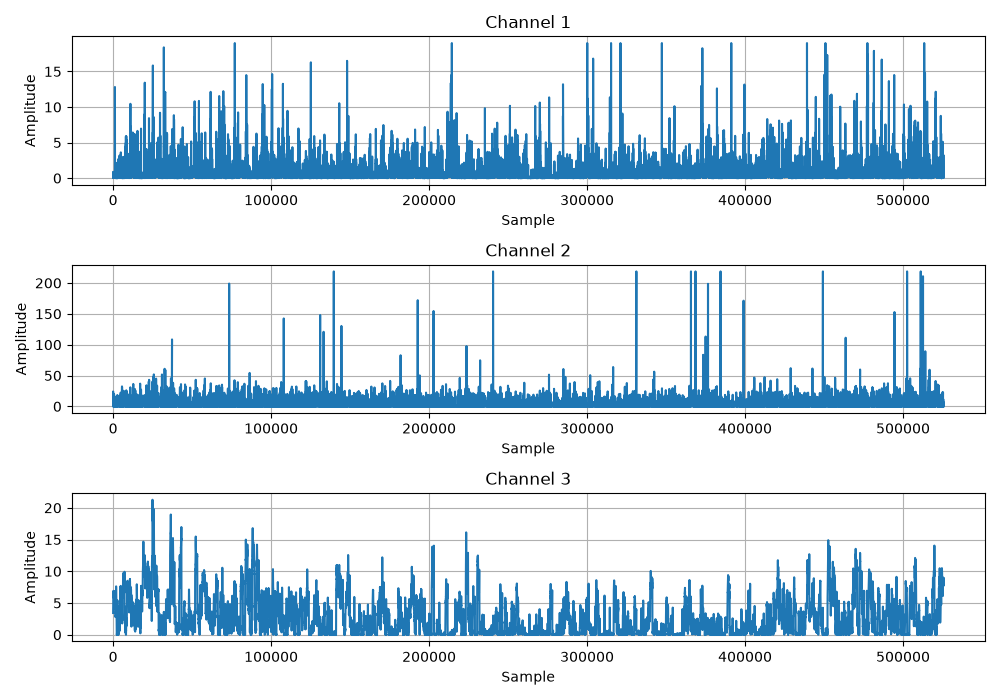

In [34]:
import matplotlib.pyplot as plt

# Tensor shape: [4, 3, 525600]
batch = raw[5]  # Shape: [3, 525600]

fig, axes = plt.subplots(3, 1, figsize=(10, 7))

for i in range(3):
    axes[i].plot(batch[i].detach().cpu().numpy())
    axes[i].set_title(f"Channel {i + 1}")
    axes[i].set_xlabel("Sample")
    axes[i].set_ylabel("Amplitude")
    axes[i].grid(True)

plt.tight_layout()
plt.show()

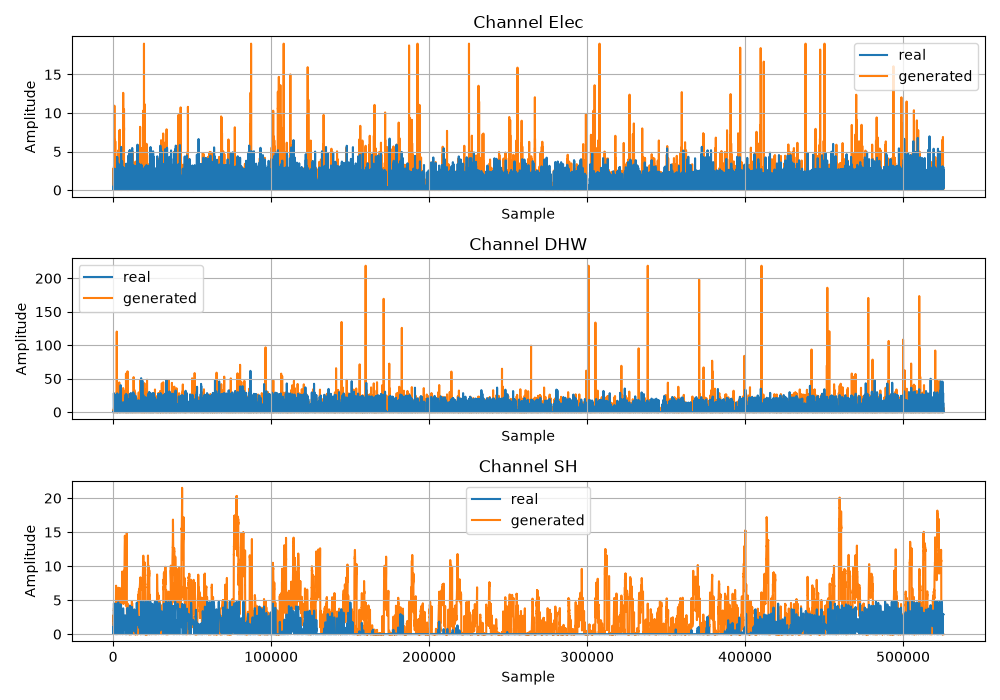

In [35]:
import matplotlib.pyplot as plt

real_year_data = pd.read_hdf(train_files[-1], key="timeseries")
batch = raw[4]
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

axes[0].plot(real_year_data["Electricity Load"].reset_index(drop=True), zorder=1, label="real")
axes[0].plot(batch[0].detach().cpu().numpy(), zorder=0, label="generated")
axes[0].set_title(f"Channel Elec")
axes[0].set_xlabel("Sample")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)
axes[0].legend()
axes[1].plot(real_year_data["Hot Water Load"].reset_index(drop=True), label="real",zorder=1)
axes[1].plot(batch[1].detach().cpu().numpy(), label="generated", zorder=0)
axes[1].set_title(f"Channel DHW")
axes[1].set_xlabel("Sample")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)
axes[1].legend()
axes[2].plot(real_year_data["Heating Load"].reset_index(drop=True), label="real",zorder=1)
axes[2].plot(batch[2].detach().cpu().numpy(), label="generated", zorder=0)
axes[2].set_title(f"Channel SH")
axes[2].set_xlabel("Sample")
axes[2].set_ylabel("Amplitude")
axes[2].grid(True)
axes[2].legend()
plt.tight_layout()
plt.show()